Saving CodeAlpha_Car_Price_Prediction_Dataset.csv to CodeAlpha_Car_Price_Prediction_Dataset.csv
Dataset Loaded Successfully!

First 5 Rows:
           name  year  selling_price  km_driven    fuel       seller_type  \
0  Maruti Swift  2016         142350     109484  Petrol            Dealer   
1   Hyundai i20  2021         315995      72548     CNG            Dealer   
2    Honda City  2016         213594      90275  Diesel        Individual   
3    Tata Nexon  2020         351197     105356  Diesel  Trustmark Dealer   
4   Maruti Alto  2015          90000      35632  Diesel        Individual   

  transmission         owner  mileage  engine  max_power  seats  
0       Manual   First Owner     22.4    1600       58.5      5  
1    Automatic   First Owner     20.1    1200       51.7      5  
2    Automatic  Second Owner     16.1    1200       49.6      5  
3       Manual   First Owner     16.1    1600       58.6      5  
4    Automatic  Second Owner     23.2    1200       85.7      5  



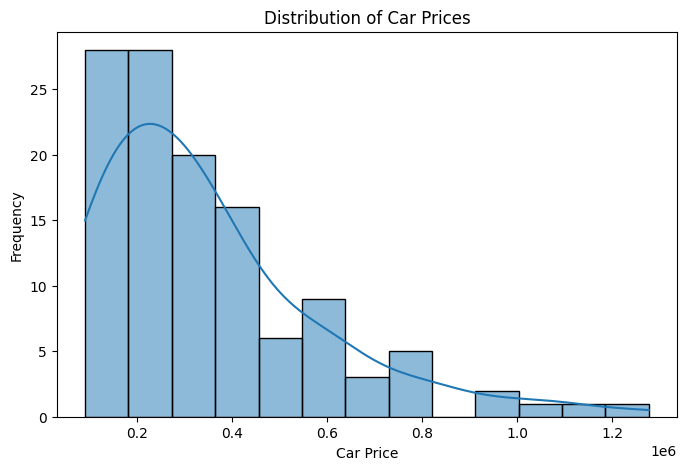

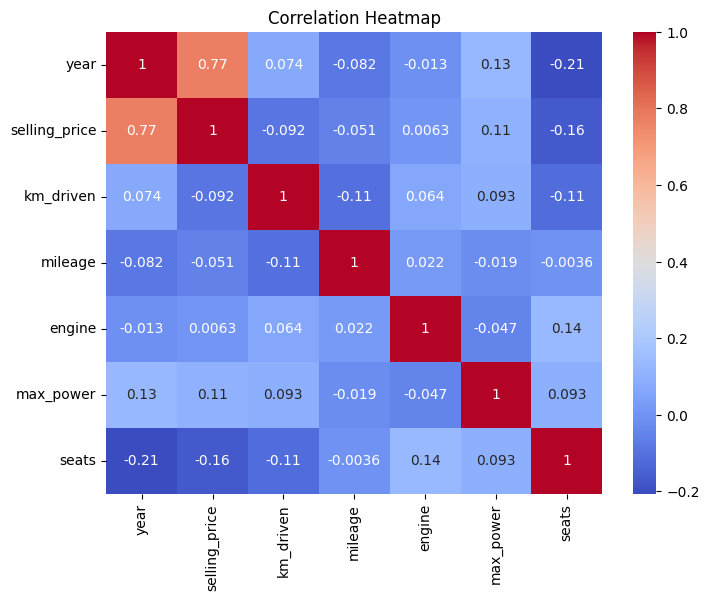


Training Data: (96, 11)
Testing Data: (24, 11)

Model Training Completed!

Predicted Car Prices:
[ 300098.79  170787.22  126975.22 1056737.83  198978.91  111653.89
  428330.12  459482.4   110559.18  168993.15]

MODEL PERFORMANCE
Mean Absolute Error: 64246.681666666664
Mean Squared Error: 6688778864.588058
Root Mean Squared Error: 81784.95500144301
R2 Score: 0.9262348985858054


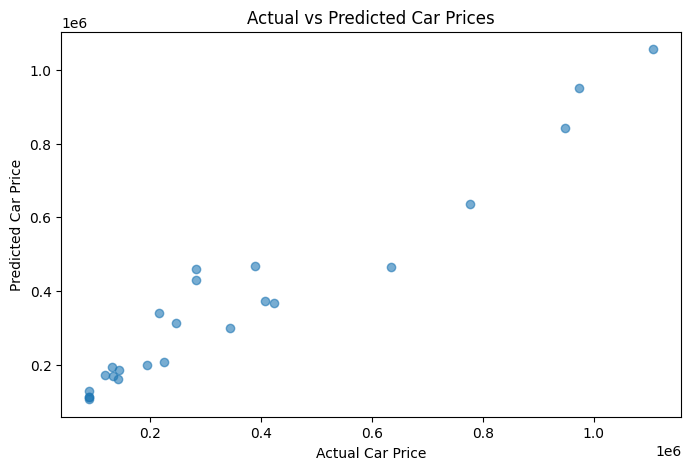


Actual vs Predicted:
   Actual Price  Predicted Price
0        342785        300098.79
1        117937        170787.22
2         90000        126975.22
3       1107348       1056737.83
4        193839        198978.91
5         90000        111653.89
6        282773        428330.12
7        281555        459482.40
8         90000        110559.18
9        132013        168993.15

Sample Car Details:
               name  year  km_driven fuel seller_type transmission  \
44  Mahindra XUV500  2019      31757  CNG      Dealer       Manual   

          owner  mileage  engine  max_power  seats  
44  First Owner     20.7    2000       70.0      5  

Predicted Car Price:
300098.79

Model Saved Successfully!

CAR PRICE PREDICTION COMPLETED!


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib


uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")



print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


print("\nMissing Values:")
print(df.isnull().sum())

df.columns = df.columns.str.strip()

target_col = None

for col in df.columns:
    if col.lower().strip() in [
        "selling_price", "selling price",
        "price", "car_price", "car price"
    ]:
        target_col = col
        break

if target_col is None:
    raise ValueError(
        "Price column not found. Check your dataset column names."
    )

print("\nTarget Column:", target_col)


df[target_col] = pd.to_numeric(
    df[target_col].astype(str).str.replace(
        r"[₹$,]", "", regex=True
    ),
    errors="coerce"
)

df = df.dropna(subset=[target_col])

df = df[df[target_col] > 0]

df = df.drop_duplicates()

print("\nCleaned Dataset:")
print(df.head())


print("\nCar Price Statistics:")
print(df[target_col].describe())

print("\nAverage Car Price:")
print(df[target_col].mean())

print("\nHighest Car Price:")
print(df[target_col].max())

print("\nLowest Car Price:")
print(df[target_col].min())


plt.figure(figsize=(8,5))

sns.histplot(df[target_col], kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.show()

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()


X = df.drop(columns=[target_col])

y = df[target_col]


numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])


model.fit(X_train, y_train)

print("\nModel Training Completed!")



y_pred = model.predict(X_test)

print("\nPredicted Car Prices:")
print(y_pred[:10])



mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)



plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Car Price")

plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()



comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(10))



sample_car = X_test.iloc[[0]]

prediction = model.predict(sample_car)

print("\nSample Car Details:")
print(sample_car)

print("\nPredicted Car Price:")
print(round(prediction[0], 2))


joblib.dump(model, "car_price_prediction_model.pkl")

print("\nModel Saved Successfully!")


print("\n==============================")
print("CAR PRICE PREDICTION COMPLETED!")
print("================================")
